### LECL：链式开发新范式
---
1. 什么是Runnable接口
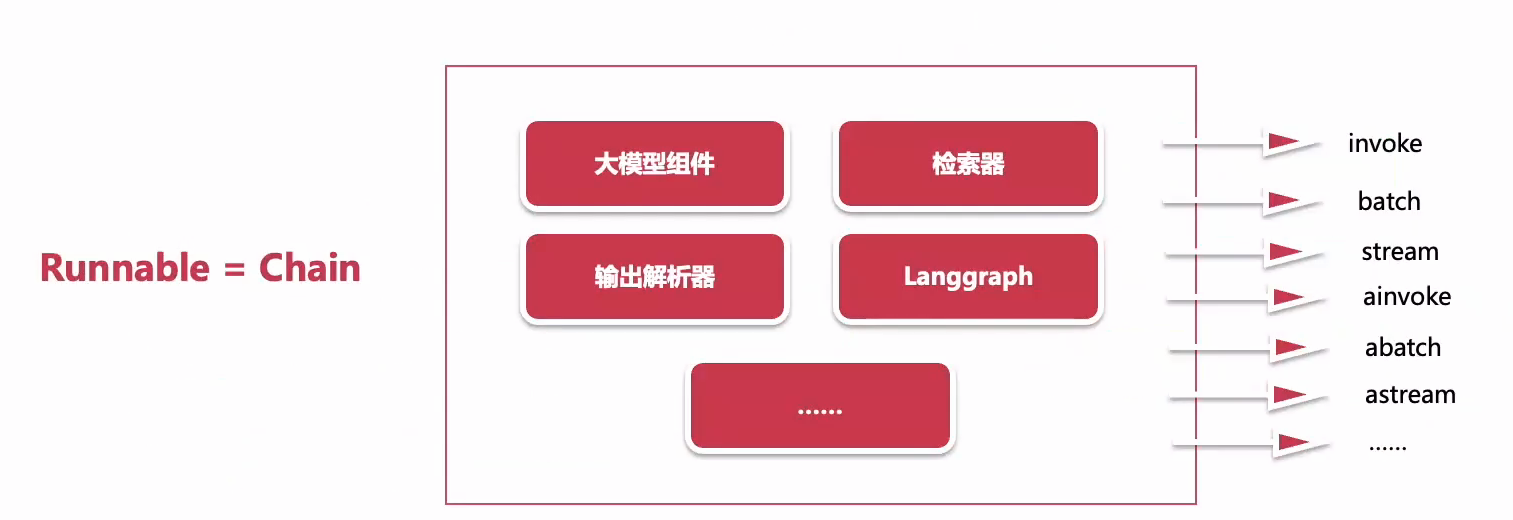

* Runnable是LangChain的核心接口,提供统一的调用方式，使不同组件可以无缝连接
* 简化了复杂AI工作流的构建过程
* 支持同步和异步操作
* 可通过了管道操作符 | 连接多个组件

注意:并不是所有的组件都支持所有的统一的调用方法，尤其是异步事件。

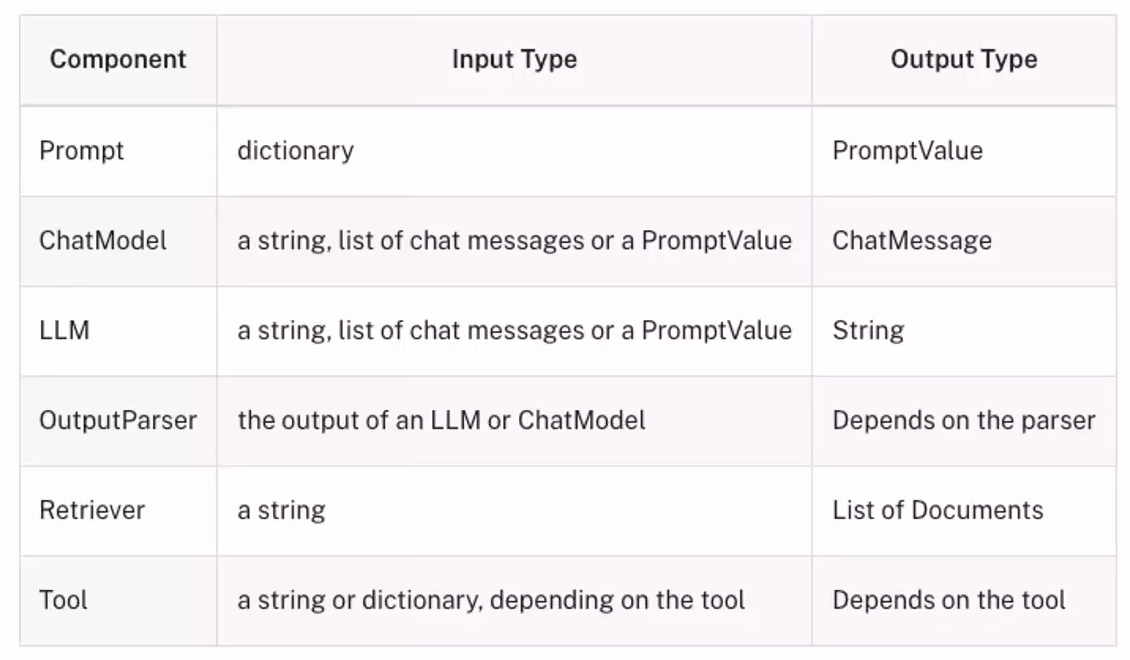

Runnable对组件的输入输出进行了强制统一(大部分报错的源头)

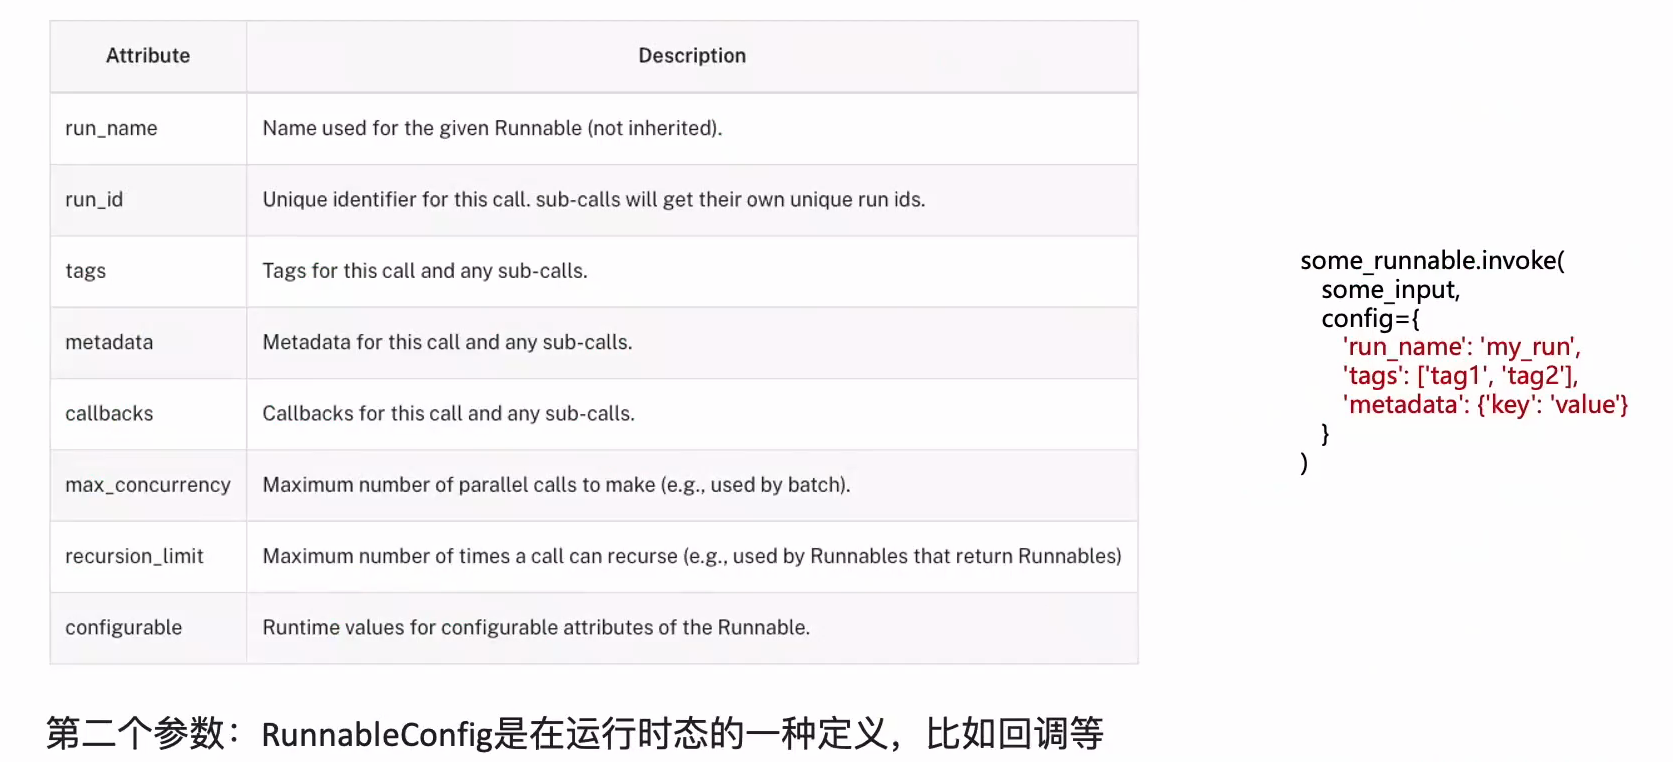

### 什么是 LangChain Expression Language (LCEL)
---
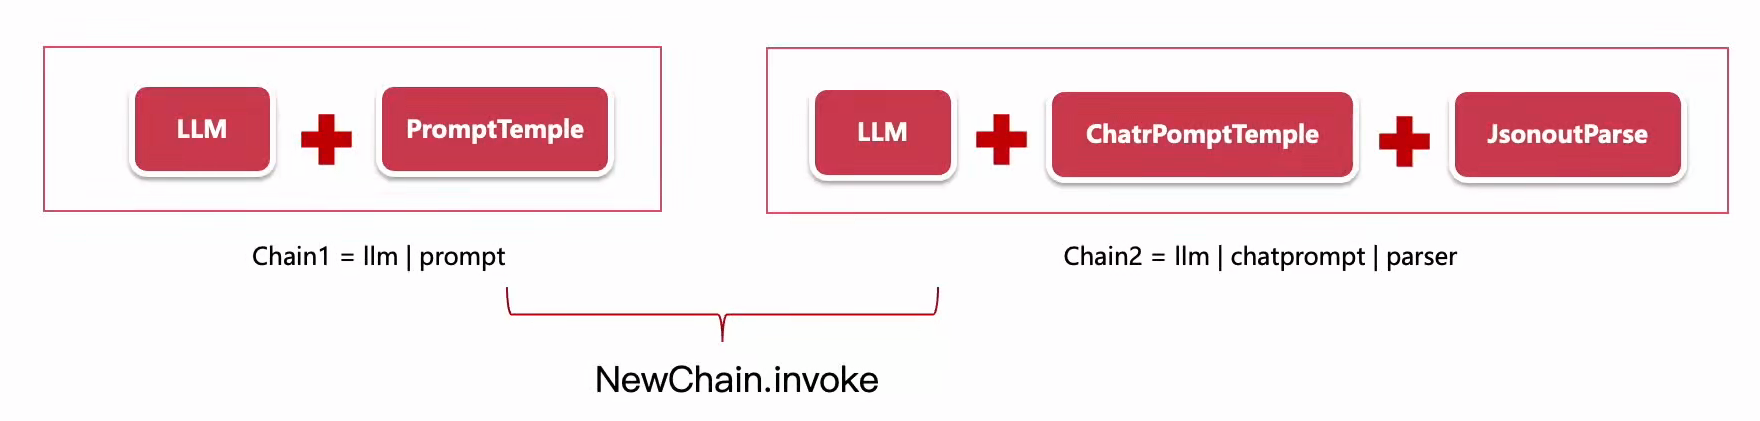

#### LCEL 的好处
* 优化的并行执行
* 稳定的异步支持
* 简化流式传输
* 标准API
* 无缝植入LangSmith追踪
* 可使用LangServe部署
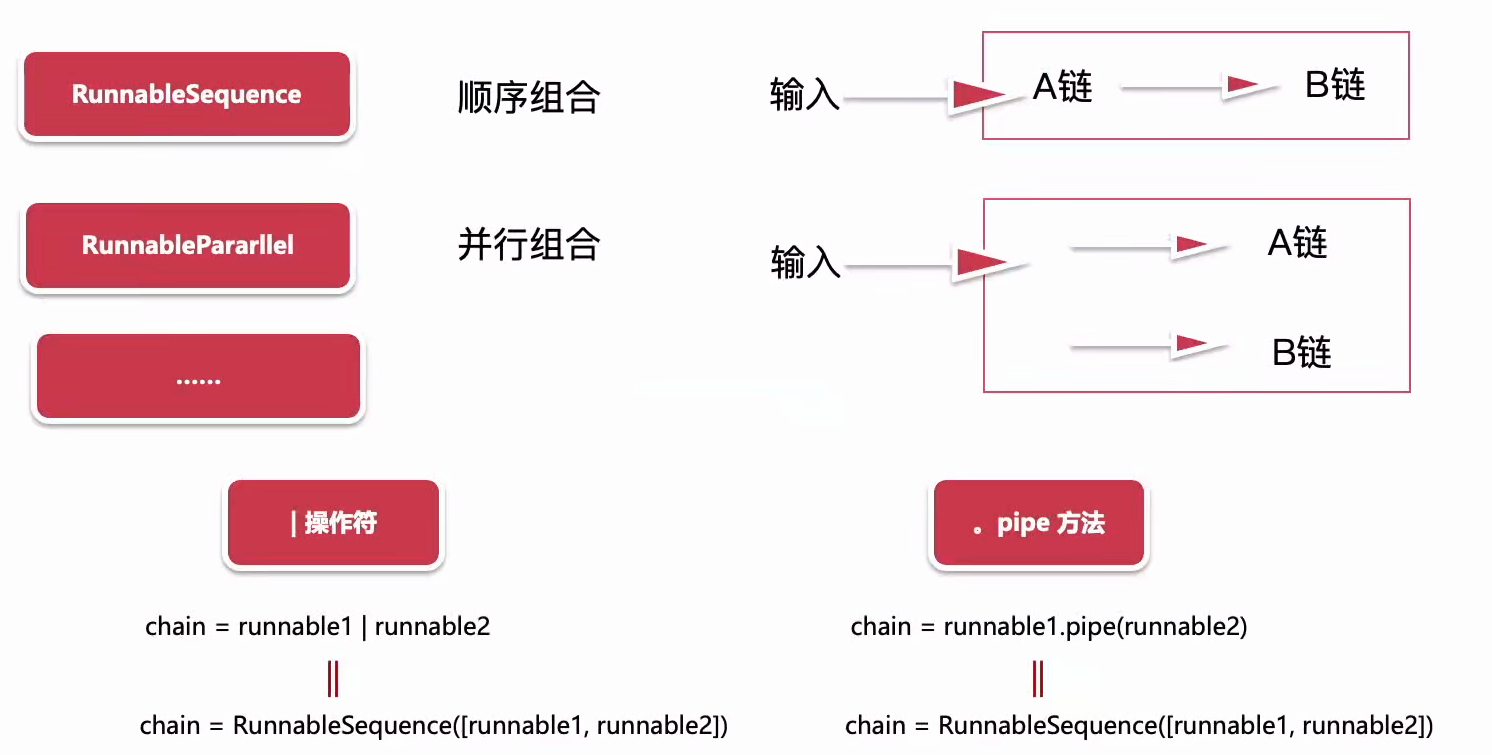

#### 使用场景
* 单个大模型调用:无需LCEL，直接调用模型即可(相当于简单使用deepseek)
* 简单链(llm+提示词+解析器)，使用LCEL最佳场景
* 构建复杂链(分支、循环、多个智能体等)，使用LangGraph
* LCEL可以嵌入在绝大部分LangChain生态应用里

#### 旧的预制链
* V0.0版本中存在大量的预制链(LLMChain、ConversationChain...)
* 在0.3版本中依然支持但建议弃用(提示词不可见无法自定义等)
* 建议使用LCEL或LangGraph方式进行自定义重构
* 迁移示例：LLMChain StuffDocumentsChain

#### 链的基本使用
* 使用管道操作符快速生成一条链
* 链的流式使用
* 并行运行多条链
* 链的调试

In [12]:
# 定义LLM
from langchain_deepseek import ChatDeepSeek

import os
from dotenv import load_dotenv

load_dotenv()

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 使用管道操作符来实现一条链
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("讲一个关于{topic}的笑话，不要有任何解释")

chain = prompt | model | StrOutputParser()
# res = chain.invoke({"topic": "狗"})

# chain = (prompt.pipe(model).pipe(StrOutputParser()))
# res = chain.invoke({"topic": "狗"})

# print(res)

for chunk in chain.stream("小狗"):
    print(chunk, end="|")


|||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||一只|小狗|在|公园|里|追|着自己的|尾巴|转|圈|。|路人|问|：“|你为什么|老|追|自己的|尾巴|？”|小狗|说|：“|因为|我不|追|它|，|它|就会|追|我|。”|||

In [13]:
# 定义LLM
from langchain_deepseek import ChatDeepSeek

import os
from dotenv import load_dotenv

load_dotenv()

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 使用管道操作符来实现一条链
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("讲一个关于{topic}的笑话，不要有任何解释")

chain = prompt | model | StrOutputParser()

async for chunk in chain.astream({"topic", "parrot"}):
    print(chunk, end="|", flush=True)

||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||

#### 链的流式使用
---
* 异步调用astream
* JSON流输出
* 使用流事件
* 注意：不是所有的组件都支持流式输出，当不支持的组件被封装在chain中后，最后的结果依旧可以使用流输出

##### 异步调用 astream
---

In [14]:
from langchain_openai import ChatOpenAI
import os

from dotenv import load_dotenv
load_dotenv

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("Tell me a joke about {topic}")
parser = StrOutputParser()
chain = prompt | model | parser

async for chunk in chain.astream({"topic": "parrot"}):
    print(chunk, end="|", flush=True)

||||||||||||||||||||||||||

|Why| did| the| par|rot| get| kicked| out| of| the| library|?|

|Because| it| kept| repeating| everything| the| librarian| said|!|||

##### JSON流输出
---

In [16]:
from langchain_core.output_parsers import JsonOutputParser

import os

from dotenv import load_dotenv
load_dotenv

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 创建一个链，将LLM的输出通过JsonOutputParser进行解析
# 注意：由于旧版本Langchain的一个bug，JsonOutputParser
chain = (model | JsonOutputParser())

# 使用astream方法进行异步流式处理
# 发送提示，要求模型以JSON格式输出法国、西班牙和日本及其人口信息
async for text in chain.astream(
    "以JSON格式输出法国、西班牙和日本的国家列表及其人口数量。"
    '使用一个字典，包含外层键名为”coutries“的国家列表'
    "每个国家应该有键名'name'和'population'"
):
    print(text, flush=True) # 打印每个流式返回的文本片段，并立即刷新输出缓冲区

{}
{'coutries': []}
{'coutries': [{}]}
{'coutries': [{'name': ''}]}
{'coutries': [{'name': '法国'}]}
{'coutries': [{'name': '法国', 'population': 6}]}
{'coutries': [{'name': '法国', 'population': 68}]}
{'coutries': [{'name': '法国', 'population': 680}]}
{'coutries': [{'name': '法国', 'population': 6800}]}
{'coutries': [{'name': '法国', 'population': 68000}]}
{'coutries': [{'name': '法国', 'population': 680000}]}
{'coutries': [{'name': '法国', 'population': 6800000}]}
{'coutries': [{'name': '法国', 'population': 68000000}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {'name': ''}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {'name': '西班牙'}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {'name': '西班牙', 'population': 4}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {'name': '西班牙', 'population': 48}]}
{'coutries': [{'name': '法国', 'population': 68000000}, {'name': '西班牙', 'population': 480}]}
{'coutries': [{'nam

##### 事件流
---
* 这是一个测试事件
* 可以将流的过程进行分解，从而事件更细颗粒度的控制
* langchain-core >= 0.2
* 事件流的颗粒度：
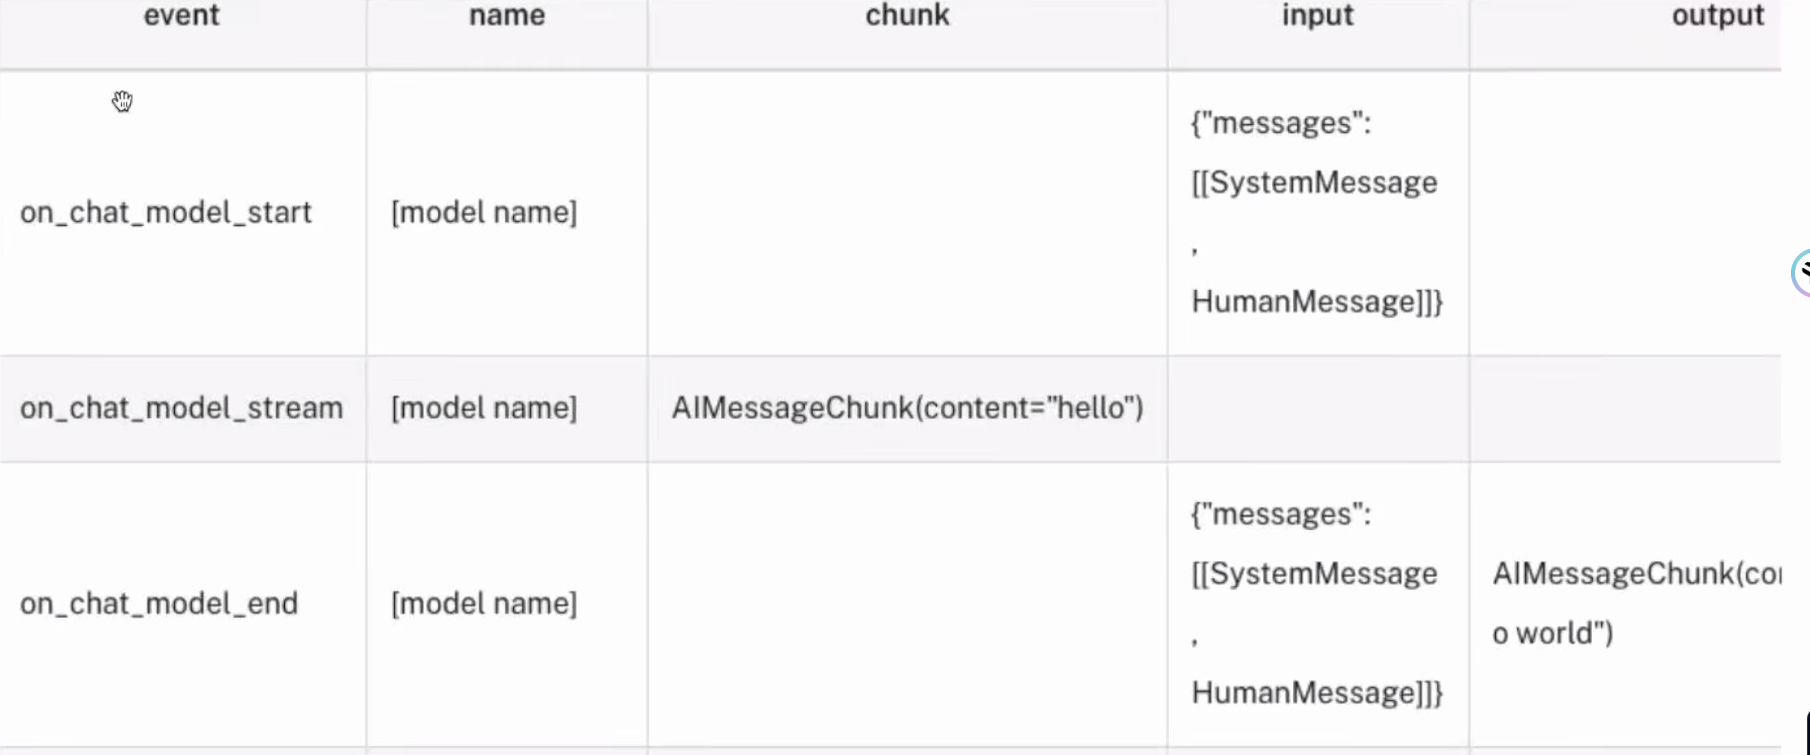
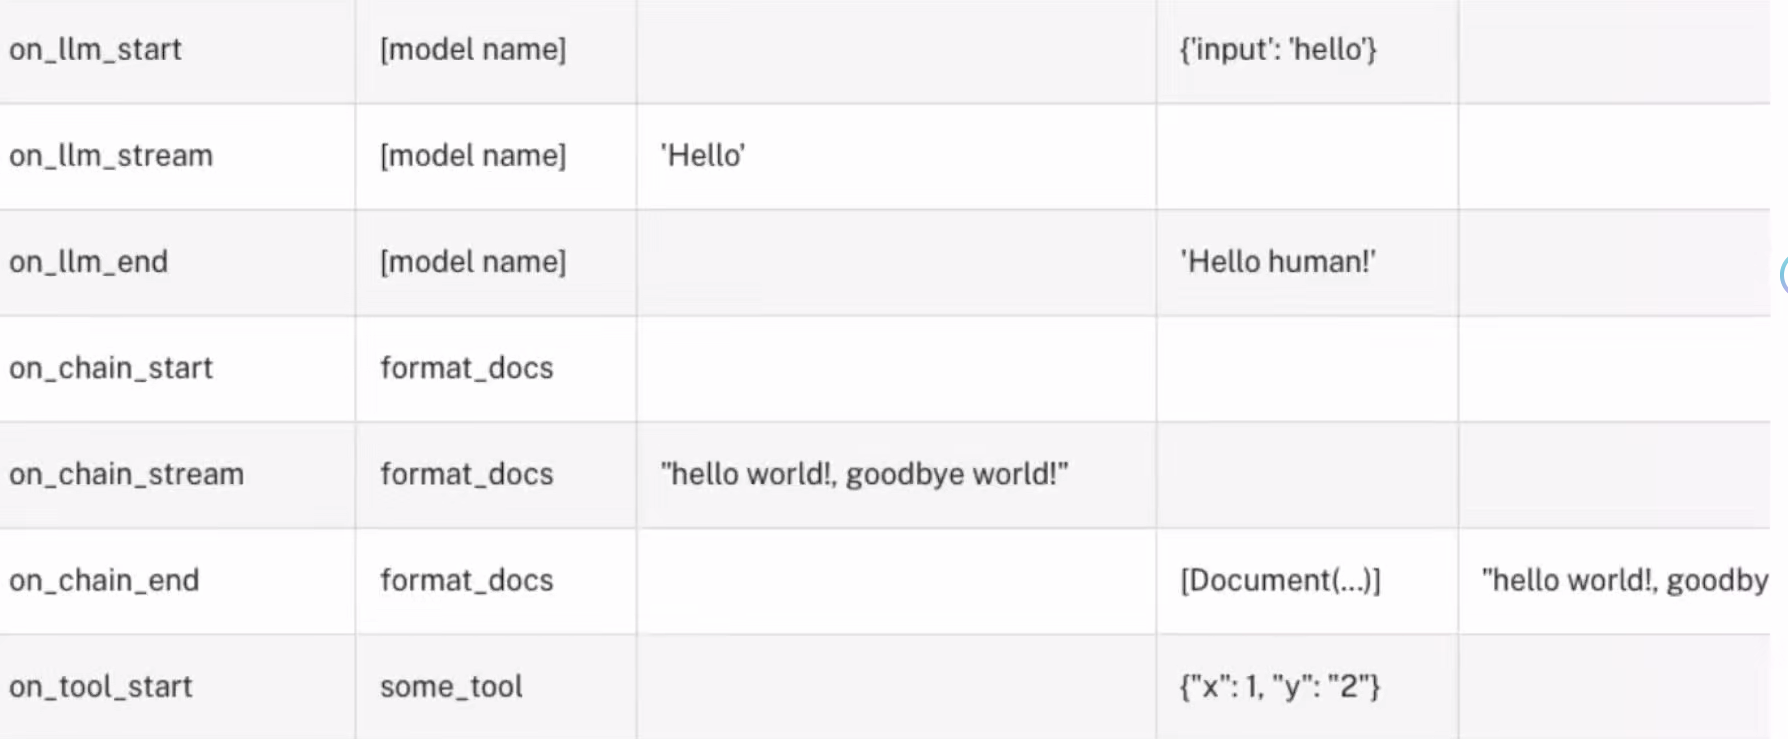
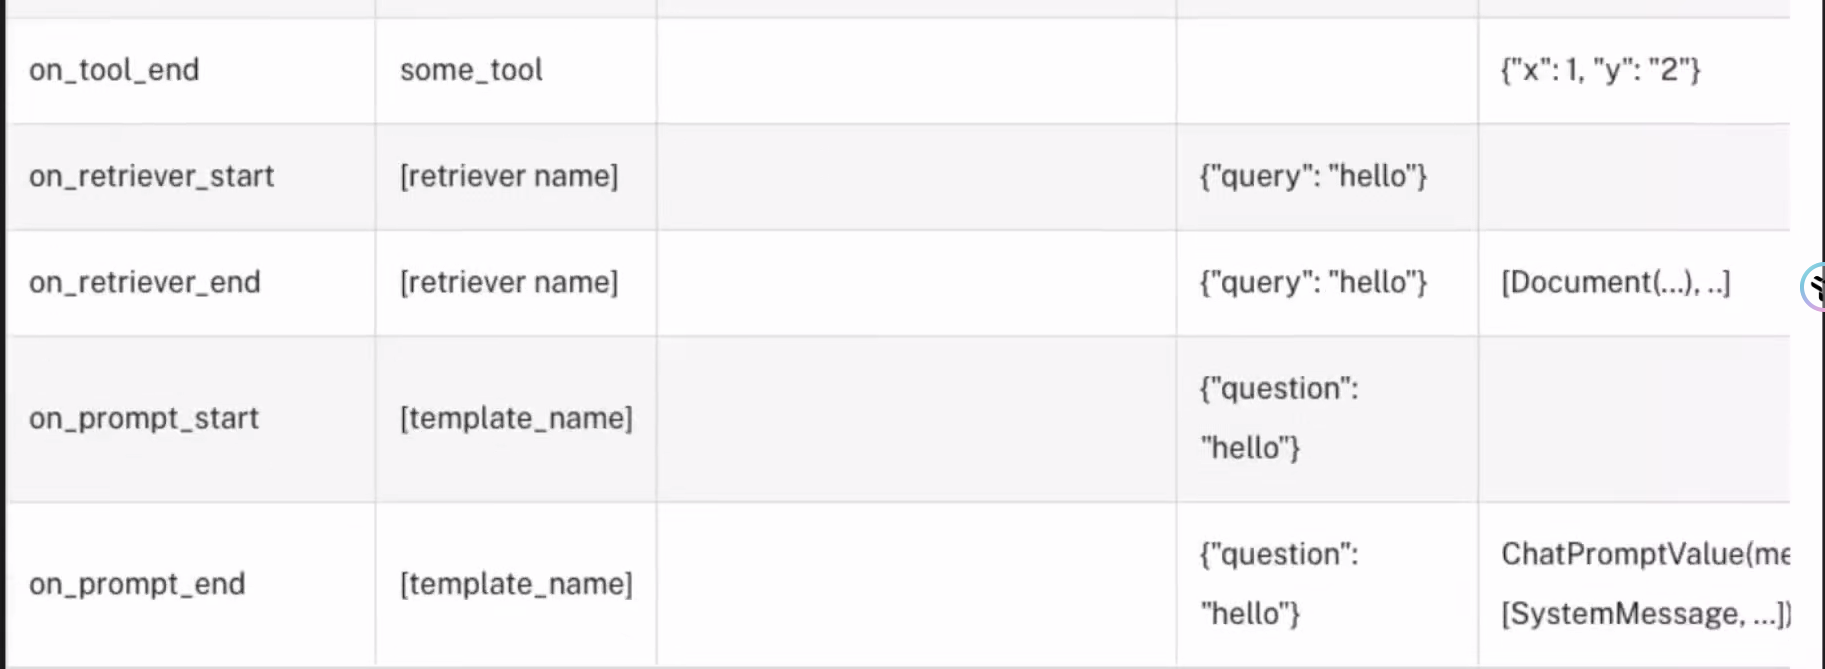

In [20]:
from langchain_core.output_parsers import JsonOutputParser

import os

from dotenv import load_dotenv
load_dotenv

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

chain = (model | JsonOutputParser())

# 注意：对于版本langchain-core<0.3.37，需要显示地指定事件流的版本
events = []
async for event in model.astream_events("hello", version="v2"):
    events.append(event)

# 查看前三个events
events[:3]

# print(events)

[{'event': 'on_chat_model_start',
  'data': {'input': 'hello'},
  'name': 'ChatOpenAI',
  'tags': [],
  'run_id': '01a1a49e-e917-7dc0-b9cd-b1c50fd27684',
  'metadata': {'ls_provider': 'openai',
   'ls_model_name': 'Qwen/Qwen3.8-27B',
   'ls_model_type': 'chat',
   'ls_temperature': 0.0,
   'ls_integration': 'langchain_chat_model',
   'lc_versions': {'langchain-core': '1.7.0',
    'langchain': '1.4.7',
    'langchain-openai': '1.7.3'}},
  'parent_ids': []},
 {'event': 'on_chat_model_stream',
  'run_id': '01a1a49e-e917-7dc0-b9cd-b1c50fd27684',
  'name': 'ChatOpenAI',
  'tags': [],
  'metadata': {'ls_provider': 'openai',
   'ls_model_name': 'Qwen/Qwen3.8-27B',
   'ls_model_type': 'chat',
   'ls_temperature': 0.0,
   'ls_integration': 'langchain_chat_model',
   'lc_versions': {'langchain-core': '1.7.0',
    'langchain': '1.4.7',
    'langchain-openai': '1.7.3'}},
  'data': {'chunk': AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'openai'}, id='lc_run-

##### 事件过滤-按name
---
按照运行时配置的name来过滤事件

In [21]:
from langchain_core.output_parsers import JsonOutputParser

import os

from dotenv import load_dotenv
load_dotenv

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

chain = model.with_config({"run_name": "model"}) | JsonOutputParser().with_config(
    {"run_name": "my_parser"}
)

max_events = 0
async for event in chain.astream_events(
    "output a list of the countries france, spain and japan and their populations in Json format. "
    'Use a dict with an outer key of "countries" which contains a list of countries. '
    "Each country should have the key `name` and `population`",
    include_names=["my_parser"],version="v2"
):
    print(event)
    max_events += 1
    if max_events > 10:
        # Truncate output
        print("...")
        break


{'event': 'on_parser_start', 'data': {'input': 'output a list of the countries france, spain and japan and their populations in Json format. Use a dict with an outer key of "countries" which contains a list of countries. Each country should have the key `name` and `population`'}, 'name': 'my_parser', 'tags': ['seq:step:2'], 'run_id': '01a1a4a6-f12f-7911-8862-b719a0e9b3d2', 'metadata': {}, 'parent_ids': ['01a1a4a6-e2fc-7b13-bef5-c6f465622f44']}
{'event': 'on_parser_stream', 'run_id': '01a1a4a6-f12f-7911-8862-b719a0e9b3d2', 'name': 'my_parser', 'tags': ['seq:step:2'], 'metadata': {}, 'data': {'chunk': {}}, 'parent_ids': ['01a1a4a6-e2fc-7b13-bef5-c6f465622f44']}
{'event': 'on_parser_stream', 'run_id': '01a1a4a6-f12f-7911-8862-b719a0e9b3d2', 'name': 'my_parser', 'tags': ['seq:step:2'], 'metadata': {}, 'data': {'chunk': {'countries': []}}, 'parent_ids': ['01a1a4a6-e2fc-7b13-bef5-c6f465622f44']}
{'event': 'on_parser_stream', 'run_id': '01a1a4a6-f12f-7911-8862-b719a0e9b3d2', 'name': 'my_parse

##### 事件过滤 - 按tag
---
按照tag来过滤事件

In [ ]:
from langchain_core.output_parsers import JsonOutputParser

import os

from dotenv import load_dotenv
load_dotenv

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

chain = (model | JsonOutputParser()).with_config({"tags": ["my_chain"]})

max_events = 0
async for event in chain.astream_events(
    "output a list of the countries france, spain and japan and their populations in Json format. "
    'Use a dict with an outer key of "countries" which contains a list of countries. '
    "Each country should have the key `name` and `population`",
    include_tags=["my_chain"],version="v2"
):
    print(event)
    max_events += 1
    if max_events > 10:
        # Truncate output
        print("...")
        break

{'event': 'on_chain_start', 'data': {'input': 'output a list of the countries france, spain and japan and their populations in Json format. Use a dict with an outer key of "countries" which contains a list of countries. Each country should have the key `name` and `population`'}, 'name': 'RunnableSequence', 'tags': ['my_chain'], 'run_id': '01a1a4ab-7ca3-7311-89c5-7e809f33e638', 'metadata': {}, 'parent_ids': []}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessage(content='output a list of the countries france, spain and japan and their populations in Json format. Use a dict with an outer key of "countries" which contains a list of countries. Each country should have the key `name` and `population`', additional_kwargs={}, response_metadata={})]]}}, 'name': 'ChatOpenAI', 'tags': ['seq:step:1', 'my_chain'], 'run_id': '01a1a4ab-7ca4-7472-a172-99091cea01f1', 'metadata': {'ls_provider': 'openai', 'ls_model_name': 'Qwen/Qwen3.8-27B', 'ls_model_type': 'chat', 'ls_tempe

##### 事件阶段过滤
---

In [ ]:
from langchain_core.output_parsers import JsonOutputParser

import os

from dotenv import load_dotenv

load_dotenv()

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

num_events = 0

async for event in chain.astream_events(
    "output a list of the countries france, spain and japan and their populations in JSON format. " 
    'Use a dict with an outer key of "countries" which contains a list of countries. '
    "Each country should have the key `name` and `population`", version="v2"
):
    kind = event["event"]
    if kind == "on_chat_model_stream":
        print(
            f"Chat model chunk: {repr(event['data']['chunk'].content)}",
            flush=True,
        )
    if kind == "on_parser_stream":
        print(f"Parser chunk: {event['data']['chunk']}", flush=True)
    num_events += 1
    if num_events > 30:
        # Truncate the output
        print("...")
        break

Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
...


In [28]:
import os
import asyncio
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser

# 1. 修复：load_dotenv 需要加上括号才能真正执行加载
load_dotenv()

# 2. 初始化模型
model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  
    base_url=os.getenv("base_url"), 
    temperature=0,
)

# 3. chain 的构建过程
parser = JsonOutputParser()

# 构建 Prompt
prompt = PromptTemplate(
    template="output a list of the countries france, spain and japan and their populations in JSON format. "
             'Use a dict with an outer key of "countries" which contains a list of countries. '
             "Each country should have the key `name` and `population`.\n{format_instructions}",
    input_variables=[],  # 因为 prompt 是写死的，没有动态变量，所以为空
    partial_variables={"format_instructions": parser.get_format_instructions()}
)

# 组装 chain
chain = prompt | model | parser

# 4. 修复：将 async for 封装在 async 函数中
async def main():
    num_events = 0
    
    # 因为 prompt 已经写死，这里传入空字典 {} 即可
    async for event in chain.astream_events({}, version="v2"):
        kind = event["event"]
        
        if kind == "on_chat_model_stream":
            print(
                f"Chat model chunk: {repr(event['data']['chunk'].content)}",
                flush=True,
            )
        if kind == "on_parser_stream":
            print(f"Parser chunk: {event['data']['chunk']}", flush=True)
            
        num_events += 1
        if num_events > 30:
            print("... (Truncated)")
            break

# 5. 运行异步函数
await main()

Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
Chat model chunk: ''
... (Truncated)
